# Question
## Assuming the time it takes a gopher to dig up to the surface is normally distributed with a mean of 4 seconds and a standard deviation of 0.8 seconds, what is the probability that a gopher appears between 3.5 and 4.5 seconds?

# Description 
### The random variable we are simulating is the time it takes for a gopher to appear. It could be 3.5 seconds or 4.5 seconds.
### A possible trial of this is a gopher appearing at 3.8 seconds. 

In [54]:
import ale_py
import gymnasium as gym

# Register the ALE environments
gym.register_envs(ale_py)

# Now check the registry
gym.pprint_registry()

===== classic_control =====
Acrobot-v1                  CartPole-v0                 CartPole-v1
MountainCar-v0              MountainCarContinuous-v0    Pendulum-v1
===== phys2d =====
phys2d/CartPole-v0          phys2d/CartPole-v1          phys2d/Pendulum-v0
===== box2d =====
BipedalWalker-v3            BipedalWalkerHardcore-v3    CarRacing-v3
LunarLander-v3              LunarLanderContinuous-v3
===== toy_text =====
Blackjack-v1                CliffWalking-v1             CliffWalkingSlippery-v1
FrozenLake-v1               FrozenLake8x8-v1            Taxi-v4
===== tabular =====
tabular/Blackjack-v0        tabular/CliffWalking-v0
===== None =====
Ant-v2                      Ant-v3                      GymV21Environment-v0
GymV26Environment-v0        HalfCheetah-v2              HalfCheetah-v3
Hopper-v2                   Hopper-v3                   Humanoid-v2
Humanoid-v3                 HumanoidStandup-v2          InvertedDoublePendulum-v2
InvertedPendulum-v2         Pusher-v2             

In [55]:
import gymnasium as gym
import matplotlib.pyplot as plt
from IPython.display import clear_output, display
import time

In [56]:
# Create environment
env = gym.make('Gopher-v4', render_mode='rgb_array')
observation, info = env.reset()

(np.float64(0.0), np.float64(1.0), np.float64(0.0), np.float64(1.0))

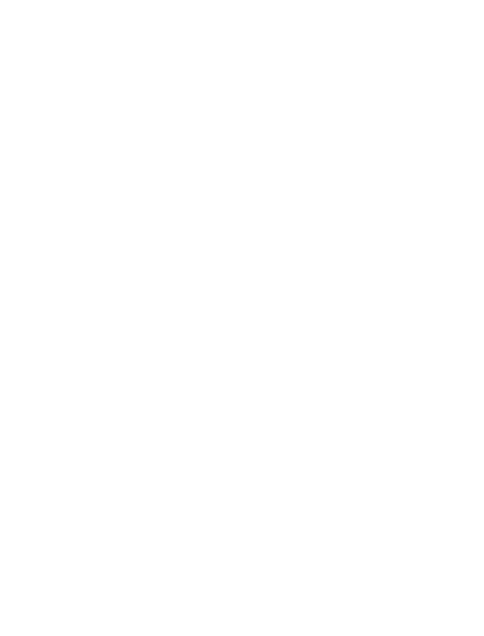

In [57]:
# Create game window
fig, ax = plt.subplots(figsize=(6, 8))
ax.axis('off')

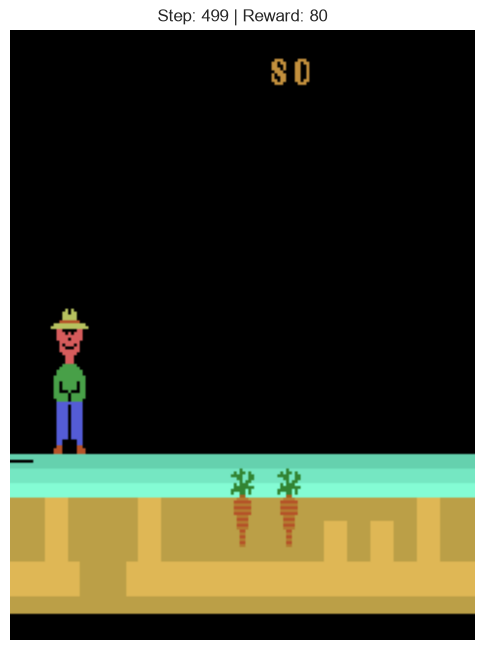

In [58]:
# Play game randomly
total_reward = 0

for step in range(500):
    # Take action
    action = env.action_space.sample()
    observation, reward, terminated, truncated, info = env.step(action)
    total_reward += reward
    
    # Clear and update display
    clear_output(wait=True)
    ax.clear()
    ax.imshow(env.render())
    ax.set_title(f"Step: {step} | Reward: {total_reward:.0f}")
    ax.axis('off')
    
    display(fig)
    
    # Add delay to make it visible (adjust this value)
    time.sleep(0.03)  # 30ms delay = ~33 fps
    
    # Reset if game over
    if terminated or truncated:
        observation, info = env.reset()
        total_reward = 0

plt.close()
env.close()

In [59]:
import numpy as np
import pandas as pd
from scipy import stats

In [60]:
np.random.seed(42)

n_trials = 1000
mean = 4.0
std_dev = 0.8

dig_times = np.random.normal(loc=mean, scale=std_dev, size=n_trials)

df = pd.DataFrame(
    {
        "trial_id": np.arange(1, n_trials + 1),
        "dig_time_seconds": dig_times,
    }
)

df.head()

,trial_id,dig_time_seconds
0,1,4.397371
1,2,3.889389
2,3,4.518151
3,4,5.218424
4,5,3.812677


In [61]:
in_range = (df["dig_time_seconds"] >= 3.5) & (df["dig_time_seconds"] <= 4.5)

simulated_prob = in_range.mean()

theoretical_prob = stats.norm.cdf(4.5, mean, std_dev) - stats.norm.cdf(
    3.5, mean, std_dev
)

print(f"Simulated Probability (1,000 trials): {simulated_prob:.4f}")
print(f"Exact Theoretical Probability: {theoretical_prob:.4f}")

Simulated Probability (1,000 trials): 0.4820
Exact Theoretical Probability: 0.4680


In [62]:
# Save simulation data to a CSV file
df.to_csv("gopher_dig_times_1000_trials.csv", index=False)

print(
    "Simulation data successfully saved to 'gopher_dig_times_1000_trials.csv'"
)

Simulation data successfully saved to 'gopher_dig_times_1000_trials.csv'


In [63]:
import matplotlib.pyplot as plt
import seaborn as sns

In [64]:
# Set default Seaborn style
sns.set_theme(style="whitegrid")

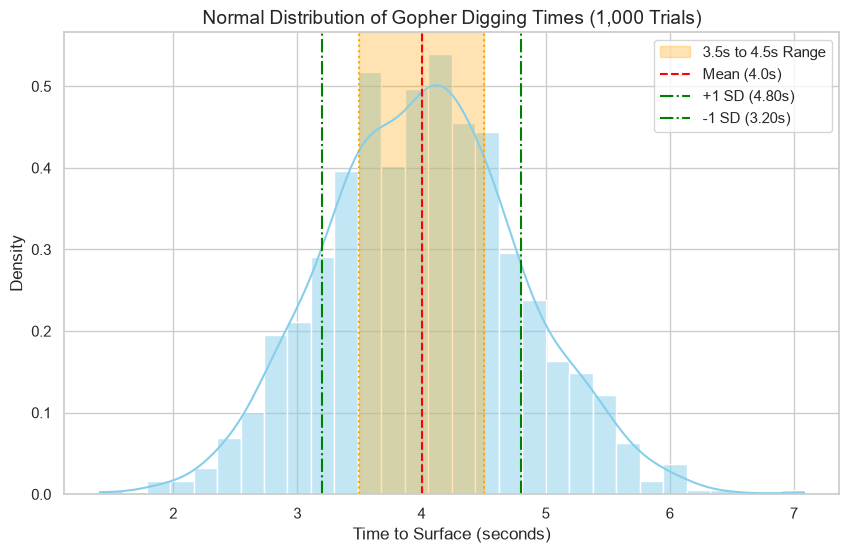

In [65]:
# Initialize figure
plt.figure(figsize=(10, 6))

# Plot histogram with Kernel Density Estimate (KDE) curve
ax = sns.histplot(
    data=df,
    x="dig_time_seconds",
    kde=True,
    color="skyblue",
    bins=30,
    stat="density",
)

# Shade the area between 3.5 and 4.5 seconds
plt.axvspan(3.5, 4.5, color="orange", alpha=0.3, label="3.5s to 4.5s Range")

# Add mean and range lines
plt.axvline(mean, color="red", linestyle="--", label=f"Mean ({mean}s)")
plt.axvline(3.5, color="orange", linestyle=":")
plt.axvline(4.5, color="orange", linestyle=":")
# Add +1 and -1 Standard Deviation lines
plt.axvline(mean + std_dev, color="green", linestyle="-.", label=f"+1 SD ({mean + std_dev:.2f}s)")
plt.axvline(mean - std_dev, color="green", linestyle="-.", label=f"-1 SD ({mean - std_dev:.2f}s)")

# Labels and Title
plt.title(
    "Normal Distribution of Gopher Digging Times (1,000 Trials)", fontsize=14
)
plt.xlabel("Time to Surface (seconds)", fontsize=12)
plt.ylabel("Density", fontsize=12)
plt.legend(loc="upper right")

# Show the plot
plt.show()

# Mean and Standard Deviation:

In [66]:
import math

# Replace this list with your probability distribution data
data = [10, 12, 23, 23, 16, 23, 21, 16]
n = len(data)

In [67]:
sum_x = sum(data)
mean = sum_x / n

print(f"Mean: {mean}")

Mean: 18.0


In [68]:
squared_diffs = [(x - mean) ** 2 for x in data]
sum_squared_diffs = sum(squared_diffs)
variance = sum_squared_diffs / (n - 1)
std_dev = math.sqrt(variance)

print(f"Standard Deviation: {std_dev}")

Standard Deviation: 5.237229365663817


# Empirical and Theoretical Probability:

In [69]:
# Define the specific outcome or threshold you are testing (e.g., rolling a 6, or scoring >= 20)
target_value = 20

In [70]:
favorable_outcomes = sum(1 for x in data if x >= target_value)
total_trials = len(data)

empirical_prob = favorable_outcomes / total_trials
print(f"Empirical Probability: {empirical_prob:.4f} ({favorable_outcomes}/{total_trials})")

Empirical Probability: 0.5000 (4/8)


In [71]:
possible_favorable_outcomes = 2
total_possible_outcomes = 6

theoretical_prob = possible_favorable_outcomes / total_possible_outcomes
print(f"Theoretical Probability: {theoretical_prob:.4f} ({possible_favorable_outcomes}/{total_possible_outcomes})")

Theoretical Probability: 0.3333 (2/6)


In [72]:
difference = abs(empirical_prob - theoretical_prob)
print(f"Difference between empirical and theoretical: {difference:.4f}")

Difference between empirical and theoretical: 0.1667


# Conclusion:
### The percentage that it will be between 3.5 and 4.5 seconds is around 67%. We can see this by taking a look at the graph and the highlighted area that the mean is right in between 3.5-4.5 seconds. Furthermore, We can see the standard deviation as ween and it falls right in the middle of it. 
### The theoretical probability is 0.3333 (2/6), and the emperical probaility is 0.5000 (4/8). This means that there were also more favorable outcomes then expected.